<a href="https://colab.research.google.com/github/034adarsh/Stock-Price-Prediction-Using-LSTM/blob/main/LSTM_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import all the required libraries

---



In [ ]:
# Our project will need these installations (once), feel free to uncomment the line below to install all packages before your first run and ONLY run this cell, then restart your kernal, comment the installation line again, and finally Run All:
# I would recommend using Python 3.11.x or Python 3.12.x
# %pip install pandas numpy matplotlib yfinance tensorflow scikit-learn joblib jinja2

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [jinja2]
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import datetime as dt
from datetime import date
import matplotlib.pyplot as plt
import yfinance as yf
import numpy as np
import tensorflow as tf
from IPython.display import display

np.random.seed(42)
tf.random.set_seed(42)

# Define start day to fetch the dataset from the yahoo finance library

---



In [3]:
START = "2013-01-01"
END = "2023-01-01"

# SPY represents the broader S&P 500 market.
# If we decide to stay with jsut Apple instead, change "SPY" to "AAPL".
TICKER = "SPY"

# Define a function to load the dataset
def load_data(ticker):
    data = yf.download(
        ticker,
        start=START,
        end=END,
        interval="1d",
        auto_adjust=False,
        multi_level_index=False,
        progress=False
    )

    data.reset_index(inplace=True)
    return data

In [4]:
data = load_data(TICKER)
df = data.copy()
df.head()

# Original code for AAPL stocks if we decide to go with Apple
# data = load_data('AAPL')
# df=data
# df.head()

,Date,Adj Close,Close,High,Low,Open,Volume
0,2013-01-02,115.705559,146.059998,146.149994,144.729996,145.110001,192059000
1,2013-01-03,115.444130,145.729996,146.369995,145.339996,145.990005,144761800
2,2013-01-04,115.951157,146.369995,146.610001,145.669998,145.970001,116817700
3,2013-01-07,115.634285,145.970001,146.110001,145.429993,145.850006,110002500
4,2013-01-08,115.301544,145.550003,145.910004,144.979996,145.710007,121265100


In [5]:
df = data[['Date', 'Close']].copy()
df.head()

# Original code:
# df = df.drop(['Date', 'Adj Close'], axis = 1)
# df.head()

,Date,Close
0,2013-01-02,146.059998
1,2013-01-03,145.729996
2,2013-01-04,146.369995
3,2013-01-07,145.970001
4,2013-01-08,145.550003


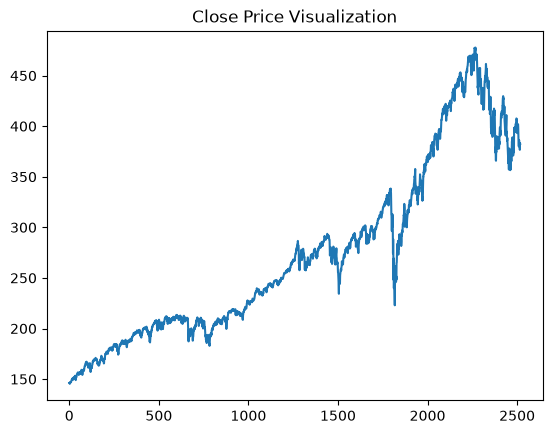

In [6]:
plt.title("Close Price Visualization")
plt.plot(df.Close)

In [7]:
df

,Date,Close
0,2013-01-02,146.059998
1,2013-01-03,145.729996
2,2013-01-04,146.369995
3,2013-01-07,145.970001
4,2013-01-08,145.550003
...,...,...
2513,2022-12-23,382.910004
2514,2022-12-27,381.399994
2515,2022-12-28,376.660004
2516,2022-12-29,383.440002


# Plotting moving averages of 100 day

---



In [8]:
ma100 = df.Close.rolling(100).mean()
ma100

0              NaN
1              NaN
2              NaN
3              NaN
4              NaN
           ...    
2513    390.736301
2514    390.408601
2515    390.040501
2516    389.745001
2517    389.455801
Name: Close, Length: 2518, dtype: float64

Text(0.5, 1.0, 'Graph Of Moving Averages Of 100 Days')

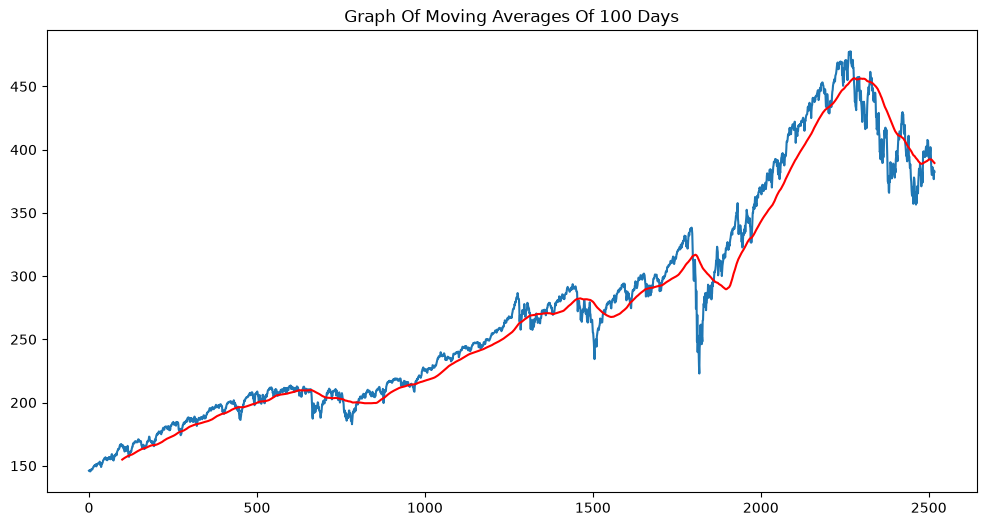

In [9]:
plt.figure(figsize = (12,6))
plt.plot(df.Close)
plt.plot(ma100, 'r')
plt.title('Graph Of Moving Averages Of 100 Days')

# Defining 200 days moving averages and plotting comparision graph with 100 days moving averages

---



In [10]:
ma200 = df.Close.rolling(200).mean()
ma200

0              NaN
1              NaN
2              NaN
3              NaN
4              NaN
           ...    
2513    400.793601
2514    400.600251
2515    400.398551
2516    400.184901
2517    399.918951
Name: Close, Length: 2518, dtype: float64

Text(0.5, 1.0, 'Comparision Of 100 Days And 200 Days Moving Averages')

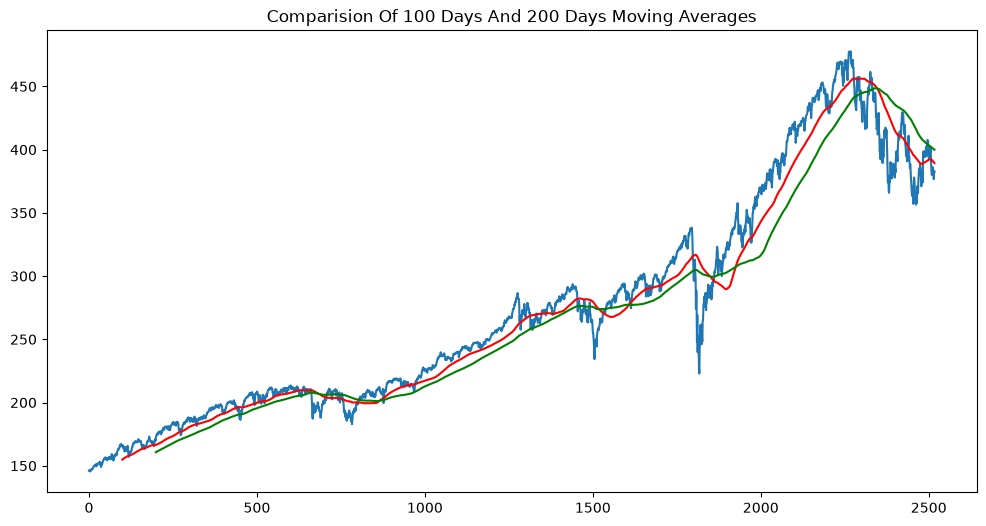

In [11]:
plt.figure(figsize = (12,6))
plt.plot(df.Close)
plt.plot(ma100, 'r')
plt.plot(ma200, 'g')
plt.title('Comparision Of 100 Days And 200 Days Moving Averages')

In [12]:
df.shape

(2518, 2)

# Spliting the dataset into training (70%) and testing (30%) set

In [13]:
# NOT splitting the dataset 70/30 for our project, new changed code is below

# Order data chronologically
data['Date'] = pd.to_datetime(data['Date'])
data = data.sort_values('Date').reset_index(drop=True)

# Model-development period
# 2013-2015 = actual model training
# 2016 = validation during training
train = data[
    (data['Date'] >= '2013-01-01') &
    (data['Date'] <= '2015-12-31')
].copy()

validation = data[
    (data['Date'] >= '2016-01-01') &
    (data['Date'] <= '2016-12-31')
].copy()

# 2017 is NOT used to train the model (this is our quiet-bull reference regime)
reference = data[
    (data['Date'] >= '2017-01-01') &
    (data['Date'] <= '2017-12-31')
].copy()

print("Training rows:", train.shape)
print("Validation rows:", validation.shape)
print("2017 reference rows:", reference.shape)

Training rows: (756, 7)
Validation rows: (252, 7)
2017 reference rows: (251, 7)


In [14]:
train.head()

,Date,Adj Close,Close,High,Low,Open,Volume
0,2013-01-02,115.705559,146.059998,146.149994,144.729996,145.110001,192059000
1,2013-01-03,115.444130,145.729996,146.369995,145.339996,145.990005,144761800
2,2013-01-04,115.951157,146.369995,146.610001,145.669998,145.970001,116817700
3,2013-01-07,115.634285,145.970001,146.110001,145.429993,145.850006,110002500
4,2013-01-08,115.301544,145.550003,145.910004,144.979996,145.710007,121265100


In [15]:
# changed from train.head() to use our validation data instead
validation.head()

,Date,Adj Close,Close,High,Low,Open,Volume
756,2016-01-04,169.051727,201.020004,201.029999,198.589996,200.490005,222353500
757,2016-01-05,169.337692,201.360001,201.899994,200.050003,201.399994,110845800
758,2016-01-06,167.201584,198.820007,200.059998,197.600006,198.339996,152112600
759,2016-01-07,163.190231,194.050003,197.440002,193.589996,195.330002,213436100
760,2016-01-08,161.398941,191.919998,195.850006,191.580002,195.190002,209817200


# Using MinMax scaler for normalization of the dataset

---



In [16]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))

In [17]:
# Changed to make sure we don't rely on column numbers but the Close instead
train_close = train[['Close']].to_numpy(dtype='float32')
validation_close = validation[['Close']].to_numpy(dtype='float32')

In [18]:
# Note: for later data only call scaler.transform instead so we don't accidentally user future market info in preprocessing
data_training_array = scaler.fit_transform(train_close)
data_training_array

array([[0.00750542],
       [0.00264883],
       [0.01206756],
       [0.006181  ],
       [0.        ],
       [0.005445  ],
       [0.02251649],
       [0.02236938],
       [0.02089763],
       [0.02236938],
       [0.02207494],
       [0.0360558 ],
       [0.04091239],
       [0.05268574],
       [0.05621767],
       [0.05680633],
       [0.06916833],
       [0.0665195 ],
       [0.07520223],
       [0.0665195 ],
       [0.06107426],
       [0.08373809],
       [0.0587194 ],
       [0.08094192],
       [0.08256078],
       [0.07961726],
       [0.09197927],
       [0.09153795],
       [0.09521699],
       [0.09713006],
       [0.09919047],
       [0.0965414 ],
       [0.11331844],
       [0.08520961],
       [0.07167029],
       [0.09330392],
       [0.05077243],
       [0.06578374],
       [0.09359813],
       [0.08918309],
       [0.0965414 ],
       [0.1084621 ],
       [0.12862372],
       [0.13171434],
       [0.13583517],
       [0.1455481 ],
       [0.15423107],
       [0.149

In [19]:
# Changed code so that our training target aims for up or down predictions rather than exact price predictions
# Example:
#   Original target:
#   $427.38
# Will instead become:
#   Your target:
#   1 = UP
#   0 = DOWN / unchanged

SEQUENCE_LENGTH = 100

x_train = []
y_train = []

for i in range(SEQUENCE_LENGTH, len(train_close)):

    # Previous 100 closing prices become the model input
    x_train.append(data_training_array[i-SEQUENCE_LENGTH:i])

    # Target:
    # 1 = today's close is higher than yesterday's close
    # 0 = today's close is equal to or lower than yesterday's close
    if train_close[i, 0] > train_close[i-1, 0]:
        y_train.append(1)
    else:
        y_train.append(0)

x_train = np.array(x_train)
y_train = np.array(y_train)

print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)

x_train shape: (656, 100, 1)
y_train shape: (656,)


In [20]:
x_train.shape

(656, 100, 1)

In [21]:
# Added new cell for validation data before the model

# Add the last 100 training days before the validation period.
# This allows the model to make a prediction for the first day of 2016
# without using future information.

validation_context = np.vstack([train_close[-SEQUENCE_LENGTH:], validation_close])

# IMPORTANT: transform only.
# Do NOT fit the scaler again.
validation_scaled = scaler.transform(validation_context)

x_val = []
y_val = []

for i in range(SEQUENCE_LENGTH, len(validation_context)):

    x_val.append(validation_scaled[i-SEQUENCE_LENGTH:i])

    if validation_context[i, 0] > validation_context[i-1, 0]:
        y_val.append(1)
    else:
        y_val.append(0)

x_val = np.array(x_val)
y_val = np.array(y_val)

print("x_val shape:", x_val.shape)
print("y_val shape:", y_val.shape)

x_val shape: (252, 100, 1)
y_val shape: (252,)


# ML Model (LSTM)

---



In [22]:
from tensorflow.keras.layers import Dense, Dropout, LSTM
from tensorflow.keras.models import Sequential

In [23]:
model = Sequential()
model.add(LSTM(units = 50, activation = 'relu', return_sequences=True ,input_shape = (x_train.shape[1], 1)))
model.add(Dropout(0.2))

model.add(LSTM(units = 60, activation = 'relu', return_sequences=True))
model.add(Dropout(0.3))

model.add(LSTM(units = 80, activation = 'relu', return_sequences=True))
model.add(Dropout(0.4))

model.add(LSTM(units = 120, activation = 'relu'))
model.add(Dropout(0.5))

# New code for our project, added because sigmoid makes the output more easily interetable
# Example: 0.90 = P(UP) = 90%
model.add(Dense(units=1, activation='sigmoid'))

# Original code line that was replaced:
# model.add(Dense(units = 1))

/Users/fujitakogi/Desktop/Stock Project/Code/Stock-Price-Prediction-Using-LSTM-main/.venv/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [24]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100, 50)        │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 50)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100, 60)        │        26,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100, 60)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 100, 80)        │        45,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 100, 80)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 120)            │        96,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           121 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 178,761 (698.29 KB)

 Trainable params: 178,761 (698.29 KB)

 Non-trainable params: 0 (0.00 B)

# Training the model

---



In [25]:
# Our new code for binary cross entropy and accuracy
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(x_train, y_train, validation_data=(x_val, y_val),epochs=50)

# Original code below calculates mean squared error
# model.compile(optimizer = 'adam', loss = 'mean_squared_error', metrics = ['MAE'])
# model.fit(x_train, y_train, validation_data = (x_test, y_test) ,epochs = 50)

Epoch 1/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 5s 116ms/step - accuracy: 0.5076 - loss: 0.6929 - val_accuracy: 0.5397 - val_loss: 0.6912
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step - accuracy: 0.5366 - loss: 0.6922 - val_accuracy: 0.5397 - val_loss: 0.6907
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 102ms/step - accuracy: 0.5366 - loss: 0.6914 - val_accuracy: 0.5397 - val_loss: 0.6907
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 99ms/step - accuracy: 0.5366 - loss: 0.6914 - val_accuracy: 0.5397 - val_loss: 0.6907
Epoch 5/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 101ms/step - accuracy: 0.5366 - loss: 0.6908 - val_accuracy: 0.5397 - val_loss: 0.6904
Epoch 6/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.5366 - loss: 0.6906 - val_accuracy: 0.5397 - val_loss: 0.6902
Epoch 7/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.5366 - loss: 0.6912 - val_accuracy: 0.5397 - val_loss: 0.6903
Epoch 8/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - accuracy: 0.5351 - loss: 0.6906 - val_accuracy: 0.53

In [26]:
# Our model for LSTM Directional Model
model.save('lstm_direction_model.keras')

import joblib
joblib.dump(scaler, 'close_price_scaler.pkl')

# Original model, only changed for clarification
# model.save('keras_model.h5')

['close_price_scaler.pkl']

**Defining the final dataset for testing by including last 100 coloums of the training dataset to get the prediction from the 1st column of the testing dataset.**

---


# Testing the model

---



In [27]:
# New code for a testing section with one shared pipeline

# Get every closing price in chronological order
all_close = data[['Close']].to_numpy(dtype='float32')

# IMPORTANT: Only use the scaler fitted on the training period, do NOT call fit_transform here!
all_scaled = scaler.transform(all_close)

x_all = []
y_all = []
target_dates = []

for i in range(SEQUENCE_LENGTH, len(data)):

    # Previous 100 days
    x_all.append(all_scaled[i-SEQUENCE_LENGTH:i])

    # Actual direction for the target day
    if all_close[i, 0] > all_close[i-1, 0]:
        y_all.append(1)
    else:
        y_all.append(0)

    target_dates.append(data.loc[i, 'Date'])

x_all = np.array(x_all)
y_all = np.array(y_all)

print("Evaluation sequences:", x_all.shape)

Evaluation sequences: (2418, 100, 1)


# Making prediction and plotting the graph of predicted vs actual values

---



In [28]:
# New code for making predictions for probability and confidence
# Example:
# If the model returns: P_Up = 0.91
# This is what we should expect to see:
#   Prediction = UP
#   Confidence = 91%

# If the model returns: P_Up = 0.08
# This is what we should expect to see:
#   Prediction = DOWN
#   Confidence = 92%



# Probability that each target day will close UP
p_up = model.predict(x_all, verbose=0).reshape(-1)

# Convert probability into UP/DOWN prediction
pred_up = (p_up >= 0.5).astype(int)

# Confidence in the class the model actually chose
confidence = np.maximum(p_up, 1.0 - p_up)

predictions = pd.DataFrame({
    'Date': pd.to_datetime(target_dates),
    'Actual_Up': y_all,
    'P_Up': p_up,
    'Pred_Up': pred_up,
    'Confidence': confidence
})

predictions.head()

# Not used for our project
# y_pred = model.predict(x_test)

,Date,Actual_Up,P_Up,Pred_Up,Confidence
0,2013-05-28,1,0.575595,1,0.575595
1,2013-05-29,0,0.575595,1,0.575595
2,2013-05-30,1,0.575595,1,0.575595
3,2013-05-31,0,0.575595,1,0.575595
4,2013-06-03,1,0.575596,1,0.575596


In [29]:
# New code for our moving average baseline

ma_df = data[['Date', 'Close']].copy()
ma_df['SMA100'] = (ma_df['Close'].rolling(100).mean())
ma_df['SMA200'] = (ma_df['Close'].rolling(200).mean())

# Create an empty signal column first
ma_signal = pd.Series(np.nan, index=ma_df.index, dtype=float)

valid_ma = (ma_df['SMA100'].notna() & ma_df['SMA200'].notna())

# If 100 day SMA > 200-day SMA, predict UP
# Otherwise predict DOWN
ma_signal.loc[valid_ma] = (ma_df.loc[valid_ma, 'SMA100'] > ma_df.loc[valid_ma, 'SMA200']).astype(int)

# Shift the signal by one day (since the prediction for today must use information that was available yesterday)
ma_df['MA_Pred_Up'] = ma_signal.shift(1)

predictions = predictions.merge(ma_df[['Date', 'MA_Pred_Up']], on='Date', how='left')
predictions.head()

,Date,Actual_Up,P_Up,Pred_Up,Confidence,MA_Pred_Up
0,2013-05-28,1,0.575595,1,0.575595,NaN
1,2013-05-29,0,0.575595,1,0.575595,NaN
2,2013-05-30,1,0.575595,1,0.575595,NaN
3,2013-05-31,0,0.575595,1,0.575595,NaN
4,2013-06-03,1,0.575596,1,0.575596,NaN


In [30]:
# New code for our ECE calculations on the probabilities that the LSTM produced

def expected_calibration_error(y_true, p_up, n_bins=5):
    y_true = np.asarray(y_true, dtype=int)
    p_up = np.asarray(p_up, dtype=float)

    # Predicted class
    predicted = (p_up >= 0.5).astype(int)

    # Confidence in chosen class
    confidence = np.maximum(p_up, 1.0 - p_up)

    # 1 = correct prediction
    # 0 = incorrect prediction
    correct = (predicted == y_true).astype(float)

    # Binary class confidence is always between 0.5 and 1.0
    bin_edges = np.linspace(0.5, 1.0, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        if i == n_bins - 1:
            in_bin = ((confidence >= bin_edges[i]) & (confidence <= bin_edges[i+1]))
        else:
            in_bin = ((confidence >= bin_edges[i]) & (confidence < bin_edges[i+1]))

        if np.any(in_bin):
            bin_accuracy = (correct[in_bin].mean())
            bin_confidence = (confidence[in_bin].mean())
            bin_weight = (in_bin.mean())
            ece += (bin_weight * abs(bin_accuracy - bin_confidence))
    return float(ece)

In [31]:
# New function to calculate directional accuracy, expected calibrated error, high confidence error rate, and moving average baseline accuracy

from sklearn.metrics import accuracy_score

# Defines High Confidence as more than 80% confident
def evaluate_regime(name, start_date, end_date, high_confidence_threshold=0.80):
    regime = predictions[
        (predictions['Date'] >= start_date) &
        (predictions['Date'] <= end_date)
    ].copy()

    y_true = regime['Actual_Up'].to_numpy(dtype=int)
    p_up = regime['P_Up'].to_numpy(dtype=float)
    y_pred = regime['Pred_Up'].to_numpy(dtype=int)
    conf = regime['Confidence'].to_numpy(dtype=float)

    directional_accuracy = accuracy_score(y_true, y_pred)

    ece = expected_calibration_error(y_true, p_up, n_bins=5)

    high_conf_mask = (conf >= high_confidence_threshold)
    if np.any(high_conf_mask):
        high_conf_error_rate = (y_pred[high_conf_mask] != y_true[high_conf_mask]).mean()
    else:
        high_conf_error_rate = np.nan

    ma_valid = (regime['MA_Pred_Up'].notna())
    if ma_valid.any():
        ma_accuracy = (regime.loc[ma_valid, 'MA_Pred_Up'].astype(int).to_numpy() == regime.loc[ma_valid, 'Actual_Up'].to_numpy()).mean()
    else:
        ma_accuracy = np.nan

    return {
        'Regime': name,
        # N is for us to see the sample size
        'N': len(regime),
        'LSTM Directional Accuracy': directional_accuracy,
        'ECE': ece,
        'High Confidence Error Rate': high_conf_error_rate,
        'High Confidence N': int(high_conf_mask.sum()),
        'MA Crossover Accuracy': ma_accuracy
    }

In [32]:
# Our regime timelines for each test and the reference
REGIMES = {
    '2017 Quiet Bull - Reference':
        (
            '2017-01-01',
            '2017-12-31'
        ),

    '2018 Choppy / Near Flat':
        (
            '2018-01-01',
            '2018-12-31'
        ),

    '2019 Strong Bull':
        (
            '2019-01-01',
            '2019-12-31'
        ),

    '2020 COVID Crash':
        (
            '2020-02-19',
            '2020-03-23'
        ),

    '2020 High Volatility Recovery':
        (
            '2020-03-24',
            '2020-09-02'
        ),

    '2022 Volatile Bear':
        (
            '2022-01-01',
            '2022-12-31'
        )
}

In [33]:
# Our table with sample size, LSTM Directional Accuracu, ECE, High Confidence Error Rate, High Confidence N, and MA Crossover Accuracy

#Defines High Confidence as more than 80% confident
results = []
for regime_name, dates in REGIMES.items():
    start_date, end_date = dates
    regime_result = evaluate_regime(regime_name, start_date, end_date, high_confidence_threshold=0.80)

    results.append(regime_result)

results_df = pd.DataFrame(results)

# Use the 2017 quiet bull regime as the reference
reference_accuracy = results_df.loc[results_df['Regime'] == '2017 Quiet Bull - Reference', 'LSTM Directional Accuracy'].iloc[0]
reference_ece = results_df.loc[results_df['Regime'] == '2017 Quiet Bull - Reference', 'ECE'].iloc[0]
reference_high_conf_error = results_df.loc[results_df['Regime'] == '2017 Quiet Bull - Reference', 'High Confidence Error Rate'].iloc[0]

# Calculate changes relative to the reference regime
results_df['Accuracy Change vs Reference'] = (results_df['LSTM Directional Accuracy'] - reference_accuracy)
results_df['ECE Change vs Reference'] = (results_df['ECE'] - reference_ece)
results_df['High Confidence Error Change vs Reference'] = (results_df['High Confidence Error Rate'] - reference_high_conf_error)

results_df

,Regime,N,LSTM Directional Accuracy,ECE,High Confidence Error Rate,High Confidence N,MA Crossover Accuracy,Accuracy Change vs Reference,ECE Change vs Reference,High Confidence Error Change vs Reference
0,2017 Quiet Bull - Reference,251,0.438247,0.320071,0.600000,110,0.561753,0.000000,0.000000,0.000000
1,2018 Choppy / Near Flat,251,0.466135,0.533865,0.533865,251,0.525896,0.027888,0.213793,-0.066135
2,2019 Strong Bull,252,0.400794,0.599206,0.599206,252,0.527778,-0.037453,0.279135,-0.000794
3,2020 COVID Crash,24,0.708333,0.291667,0.291667,24,0.291667,0.270086,-0.028404,-0.308333
4,2020 High Volatility Recovery,114,0.324561,0.675439,0.675439,114,0.412281,-0.113686,0.355368,0.075439
5,2022 Volatile Bear,251,0.581673,0.418327,0.418327,251,0.529880,0.143426,0.098256,-0.181673


In [34]:
# Our cell for better data readability 
display(results_df.style.format({
    'LSTM Directional Accuracy': '{:.2%}',
    'ECE': '{:.3f}',
    'High Confidence Error Rate': '{:.2%}',
    'MA Crossover Accuracy': '{:.2%}'
}))

AttributeError: The '.style' accessor requires jinja2